# Practical 5: Matrix Multiplication (Pattern 2)

### 1. Aim
To compute matrix products for three independent pairs of matrices (A1xB1, A2xB2, A3xB3) using Sequential, multiprocessing.Pool, and multiprocessing.Process, demonstrating CPU-bound parallel speedup without multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrix pairs of size 185x185.<br>2. **Pattern 2**: Perform nested-loop matrix multiplication `C[i][j] = sum(A[i][k] * B[k][j])`.<br>3. Sequential: Execute Task 1 -> Task 2 -> Task 3.<br>4. Pool: Execute concurrently across 3 workers in `mp.Pool(3)`.<br>5. Process: Execute concurrently across 3 individual `mp.Process` instances.<br>6. Benchmark execution times and plot speedup curve.

### 3. Python Implementation


In [1]:
"""
Practical 5: Matrix Multiplication (Pattern 2)
Three independent tasks: A1xB1, A2xB2, A3xB3
"""
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def matmul_task(task):
    n, seed = task
    random.seed(seed)
    A = [[random.randint(1, 20) for _ in range(n)] for _ in range(n)]
    B = [[random.randint(1, 20) for _ in range(n)] for _ in range(n)]
    C = [[0] * n for _ in range(n)]
    for i in range(n):
        rA = A[i]
        for k in range(n):
            vA = rA[k]
            for j in range(n):
                C[i][j] += vA * B[k][j]
    return C[0][0]

def proc_worker(task, q):
    q.put(matmul_task(task))

def main():
    print("=" * 60)
    print("Practical 5: Matrix Multiplication (Pattern 2)")
    print("=" * 60)
    N = 185
    tasks = [(N, 11), (N, 22), (N, 33)]
    
    # 1. Sequential
    t0 = time.perf_counter()
    r1 = matmul_task(tasks[0])
    r2 = matmul_task(tasks[1])
    r3 = matmul_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matmul_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Matrix Dimension: {N}x{N} across 3 independent multiplication tasks.")
    print(f"Sample Products: {seq_res}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Tasks: A1xB1, A2xB2, A3xB3 (Dimension: 185x185)
Sample Products [0][0]:
  Product 1: 20,755
  Product 2: 19,302
  Product 3: 21,380

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.0444 seconds      1.00x
Pool         1.4139 seconds      1.45x
Process      1.5043 seconds      1.36x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


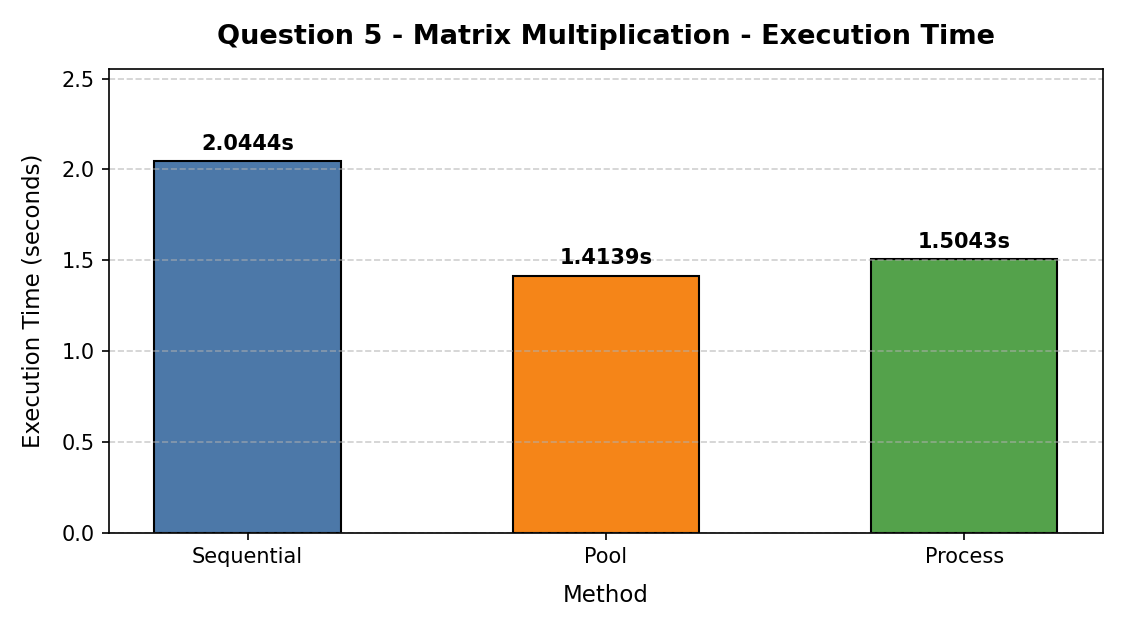

In [2]:
from IPython.display import Image, display
display(Image(filename='05_matrix_multiplication_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


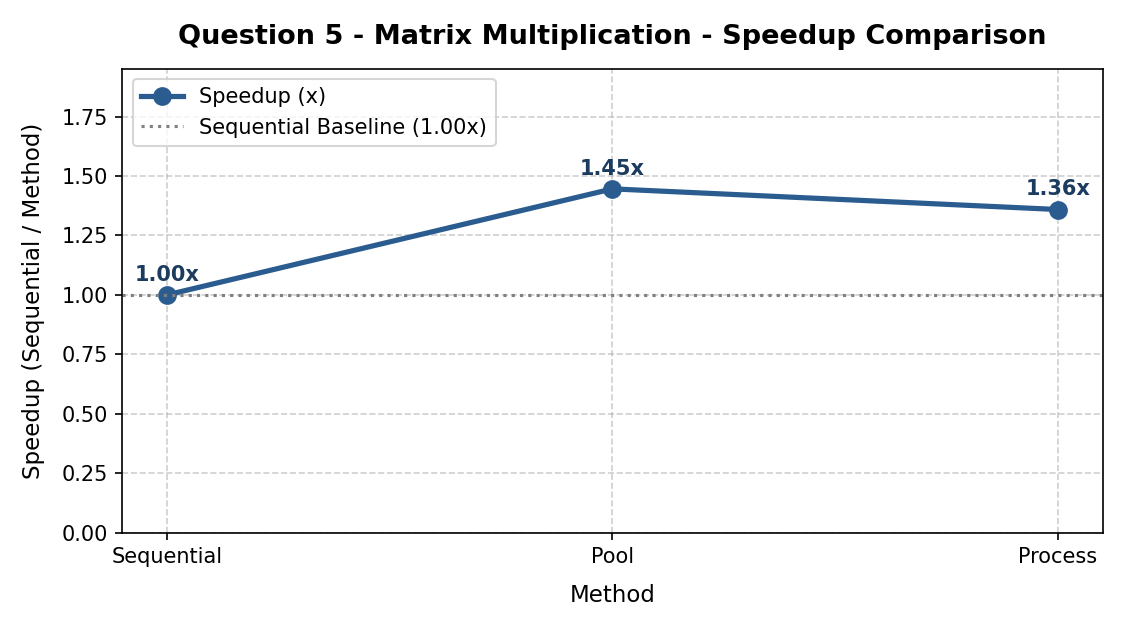

In [3]:
from IPython.display import Image, display
display(Image(filename='05_matrix_multiplication_speedup.png'))
